# Comprehension and Fixation Analysis by Wave

Wave 1 and Wave 2 are loaded and analyzed independently. The sections are presented vertically to make direct visual comparisons easier without merging the observations.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = Path.cwd()
while not (ROOT / 'pyproject.toml').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from analysis.comprehension.io import load_counts, sample_summary
from analysis.comprehension.models import fit_poisson_diagnostic, fit_primary, fit_reverse
from analysis.comprehension.plots import (
    plot_distributions, plot_jittered_association, plot_text_facets,
    plot_group_estimates, plot_language_text_heatmap, plot_participant_association,
    plot_model_diagnostics, plot_model_coefficients, plot_model_effects,
)

OUTPUT = ROOT / 'analysis' / 'comprehension' / 'output' / 'by_wave'
OUTPUT.mkdir(parents=True, exist_ok=True)

## Shared Plot Scale

The y-axis limits are calculated once from both waves for visual comparability. This does not combine the data for analysis; it only provides a common plotting scale.

## Wave 1

Participant-text observations: 6,501; participants: 542


,wave,lang,participants,participant_text_rows,texts,mean_comprehension,mean_fixations_per_word
0,1,du,46,552,12,0.742754,1.202702
1,1,ee,58,696,12,0.781609,1.301527
2,1,en,45,540,12,0.737037,0.993022
3,1,fi,51,612,12,0.750817,1.216215
4,1,ge,45,540,12,0.730556,1.399680
5,1,gr,48,575,12,0.582609,1.332026
6,1,he,45,540,12,0.744444,1.678735
7,1,it,51,611,12,0.725859,1.530587
8,1,no,40,480,12,0.664583,1.298869
9,1,ru,47,564,12,0.746454,1.344046


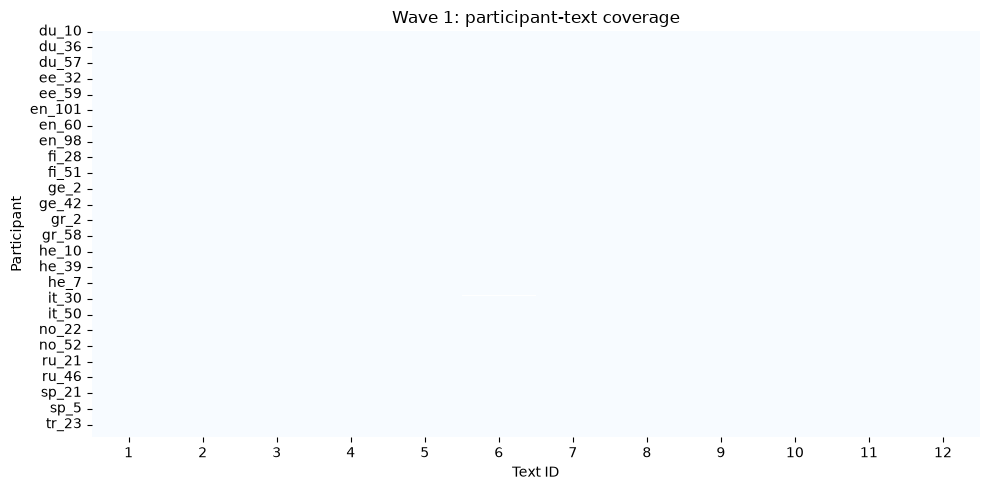

## Wave 2

Participant-text observations: 7,695; participants: 658


,wave,lang,participants,participant_text_rows,texts,mean_comprehension,mean_fixations_per_word
0,2,ba,35,418,12,0.740431,1.437387
1,2,bp,54,647,12,0.761978,1.364993
2,2,ch_s,46,355,12,0.692958,1.522207
3,2,ch_t,42,504,12,0.647817,2.283933
4,2,da,25,300,12,0.728333,1.331366
5,2,en_uk,50,600,12,0.733333,0.956820
6,2,ge_po,43,516,12,0.749031,1.322054
7,2,ge_zu,47,564,12,0.740248,1.207506
8,2,hi_iiith,53,636,12,0.729560,1.171655
9,2,hi_iitk,45,540,12,0.746296,1.207498


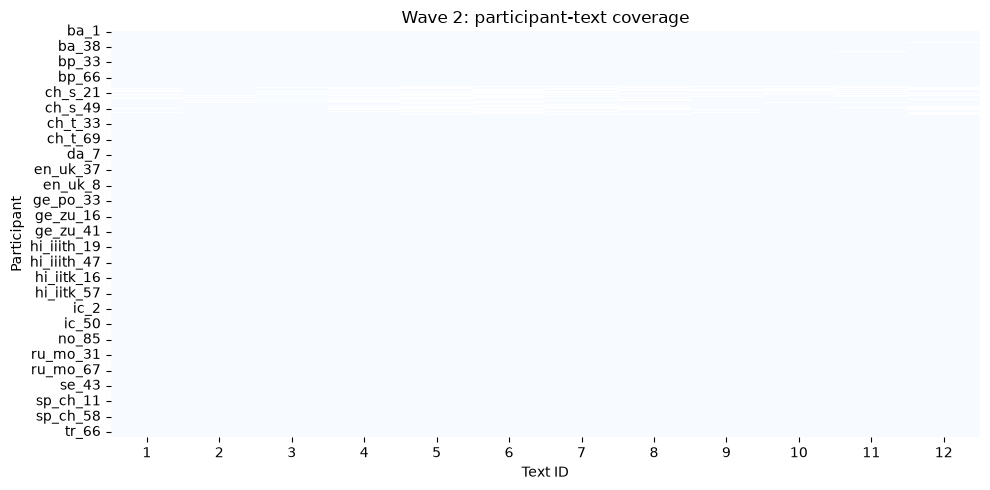

In [2]:
wave_data = {1: load_counts('1'), 2: load_counts('2')}
shared_upper = max(wave_data[1]['fixations_per_word'].quantile(0.995), wave_data[2]['fixations_per_word'].quantile(0.995)) * 1.05
global_ylim = (0, shared_upper)
for wave, data in wave_data.items():
    display(Markdown(f'## Wave {wave}'))
    print(f'Participant-text observations: {len(data):,}; participants: {data.participant_id.nunique():,}')
    display(sample_summary(data))
    (OUTPUT / f'wave-{wave}').mkdir(parents=True, exist_ok=True)
    data.to_csv(OUTPUT / f'wave-{wave}' / 'analysis_dataset.csv', index=False)
    coverage = data.pivot_table(index='participant_id', columns='text_id', values='comprehension_score', aggfunc='size')
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.heatmap(coverage, cmap='Blues', cbar=False, ax=ax)
    ax.set(title=f'Wave {wave}: participant-text coverage', xlabel='Text ID', ylabel='Participant')
    fig.tight_layout()
    fig.savefig(OUTPUT / f'wave-{wave}' / 'coverage.png', dpi=160)
    display(fig)
    plt.close(fig)

## Wave-Specific Exploratory Plots

Each wave is plotted separately below. The plotting helpers suppress the redundant one-wave legend.

### Wave 1

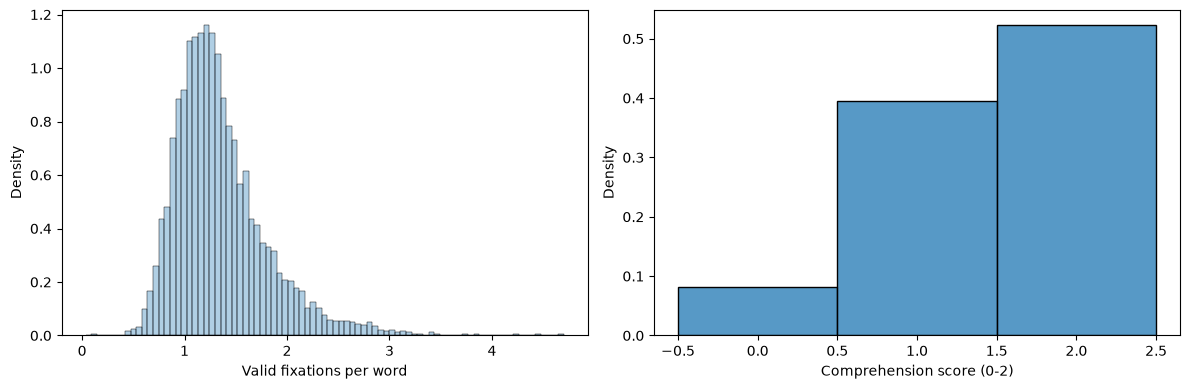

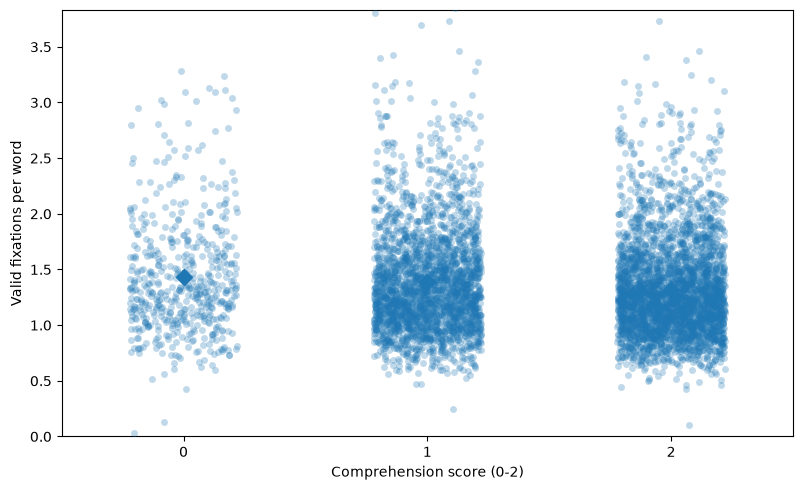

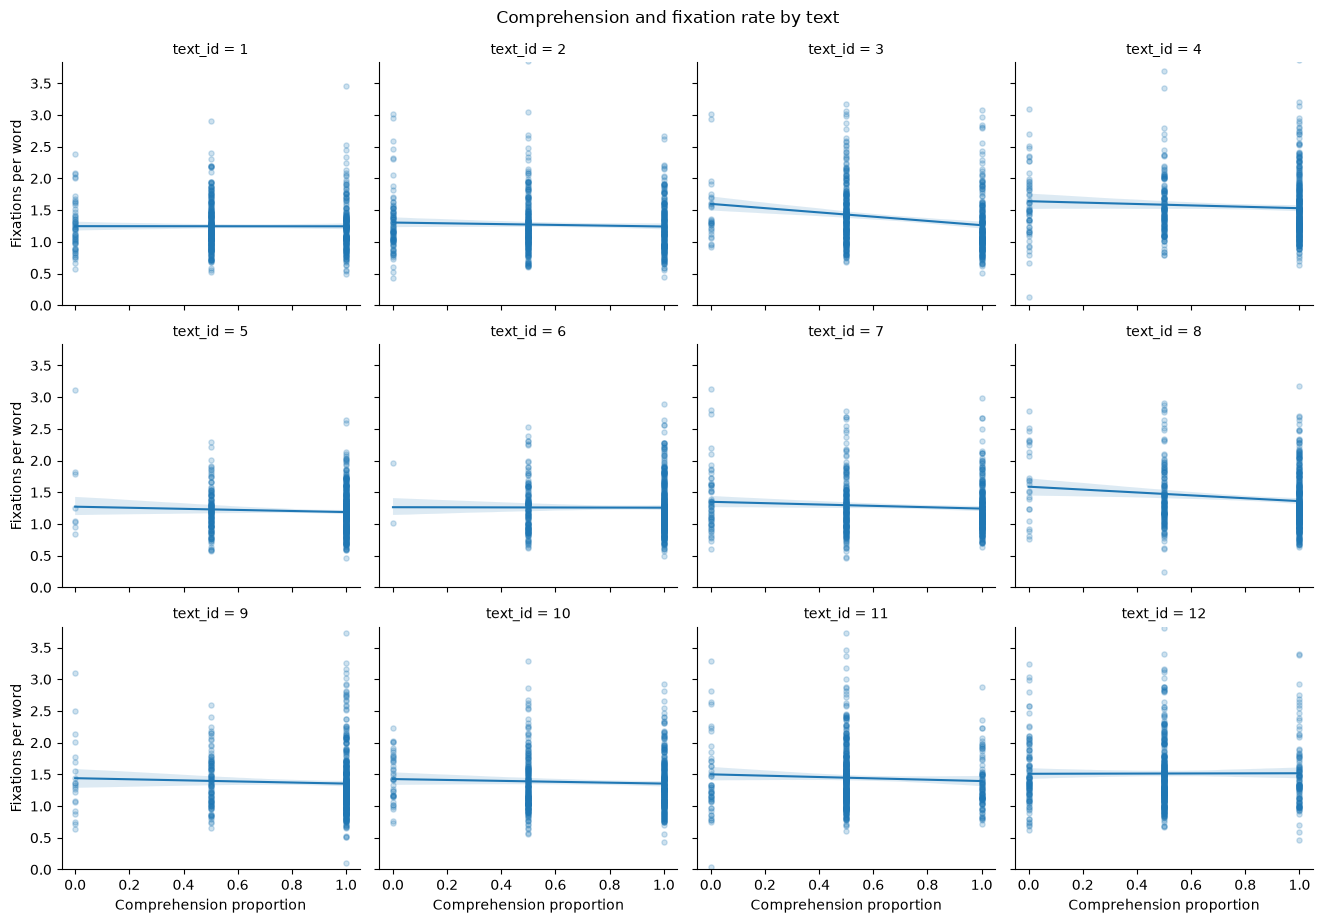

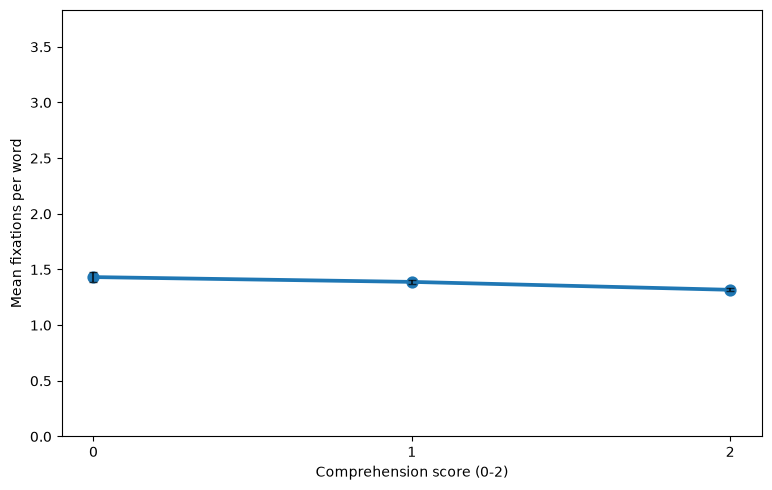

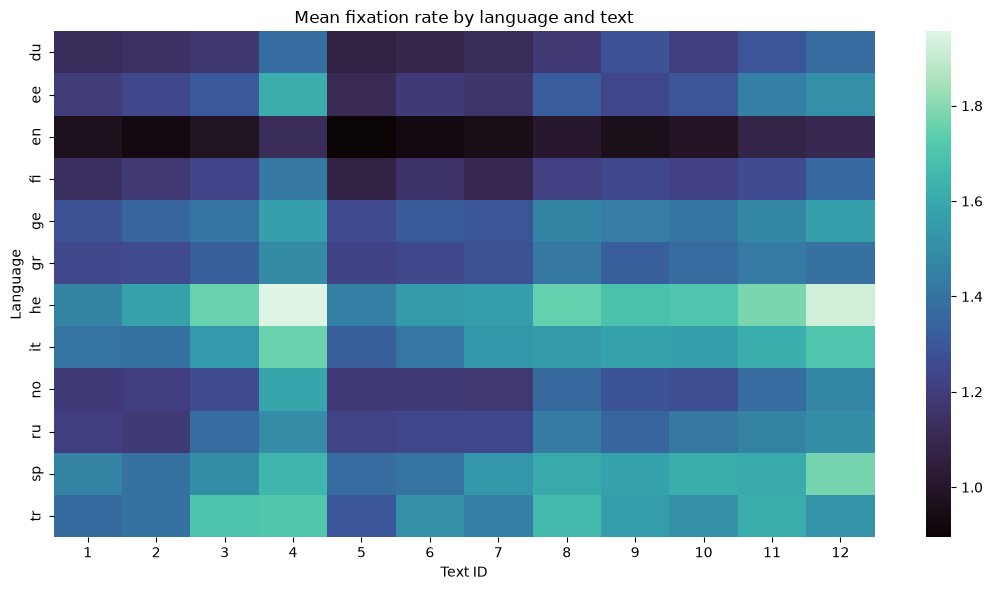

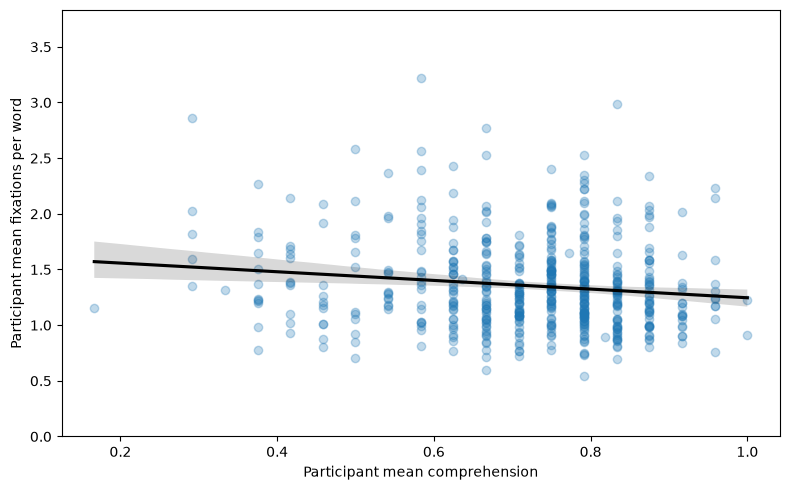

### Wave 2

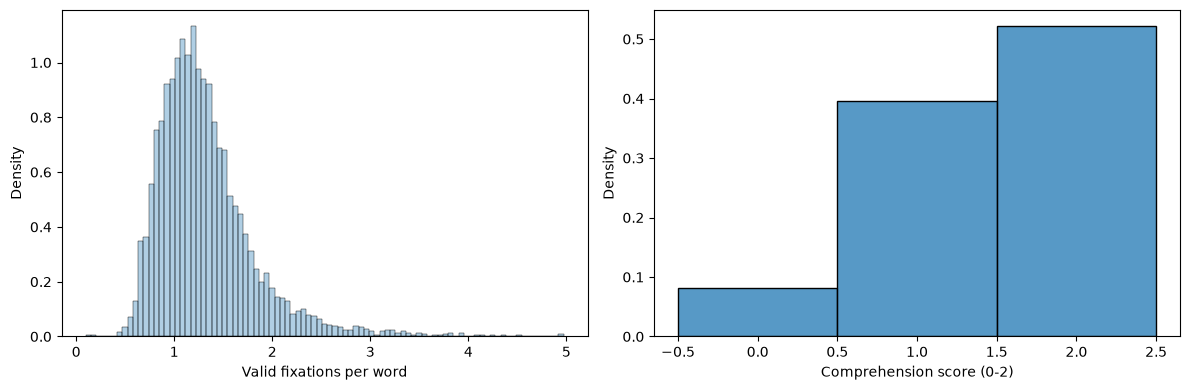

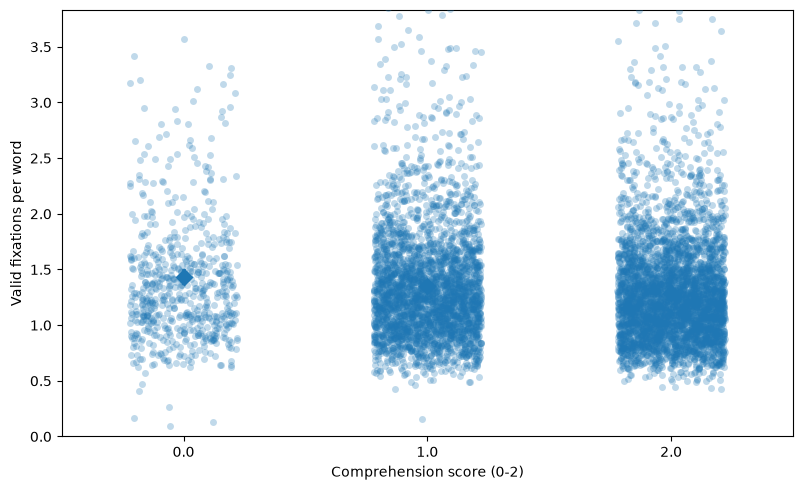

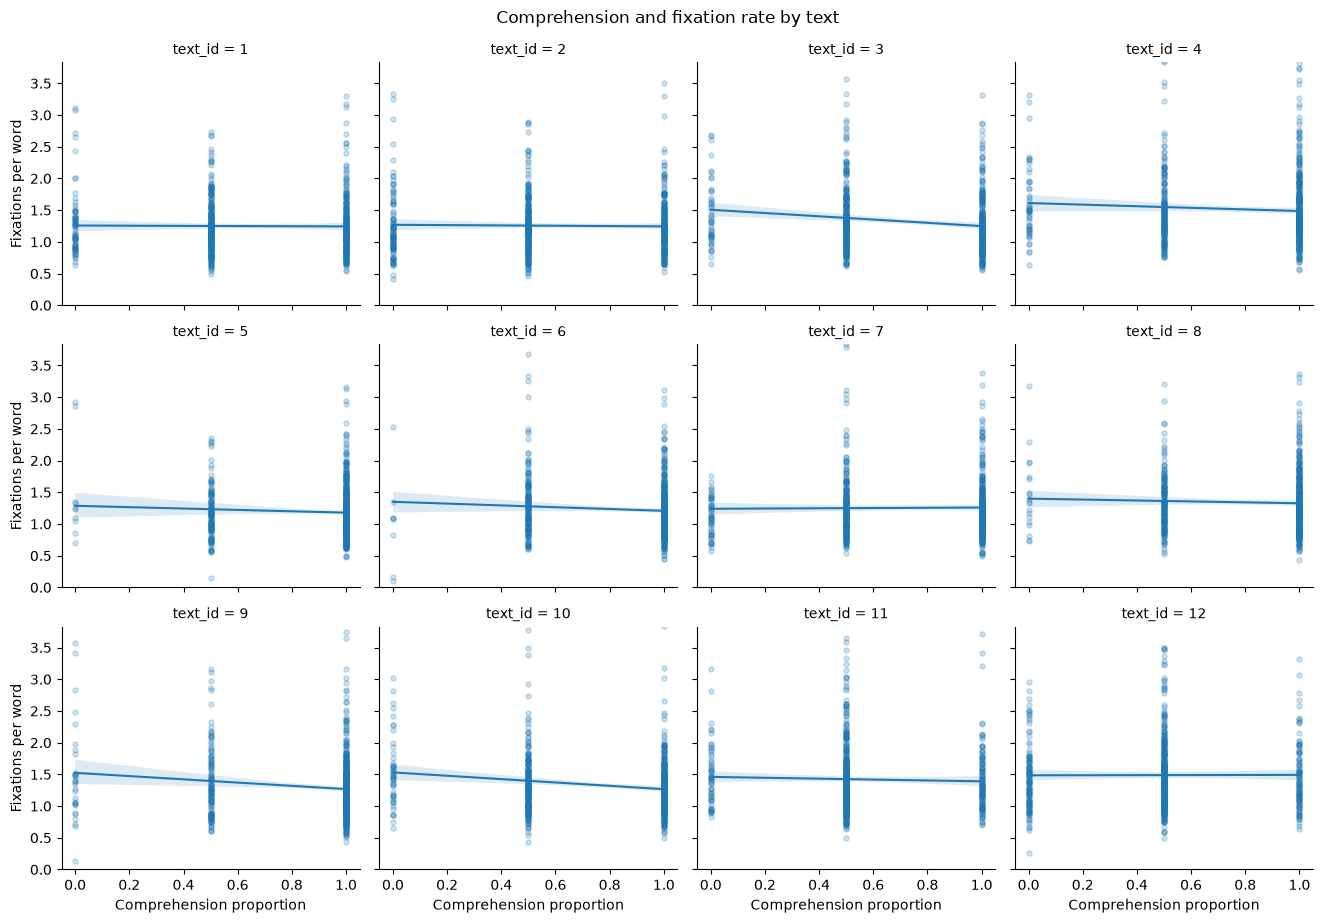

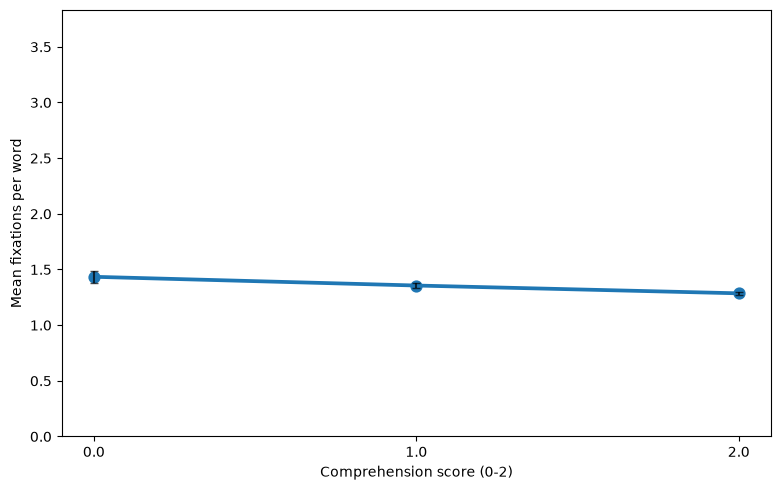

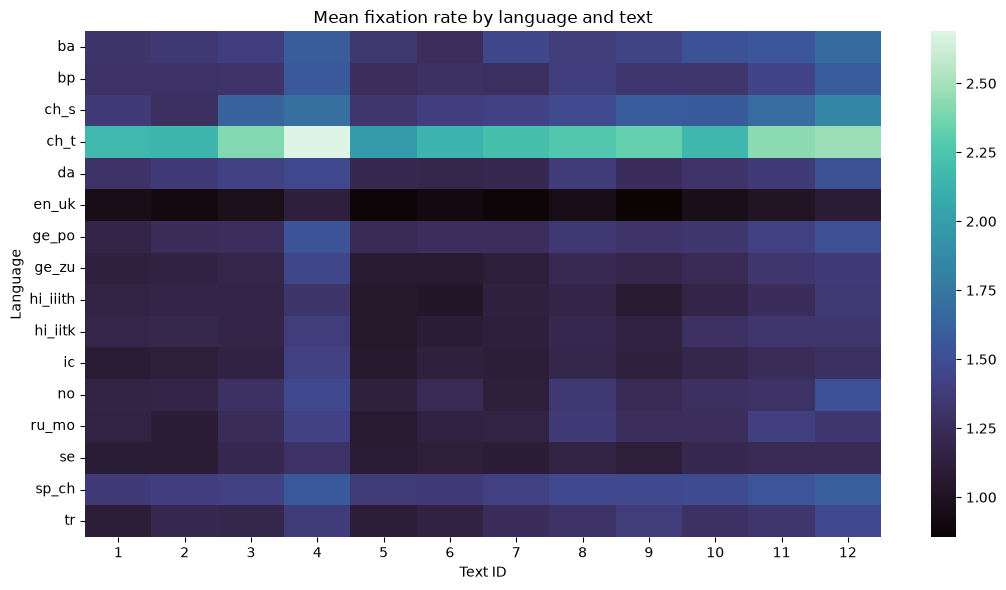

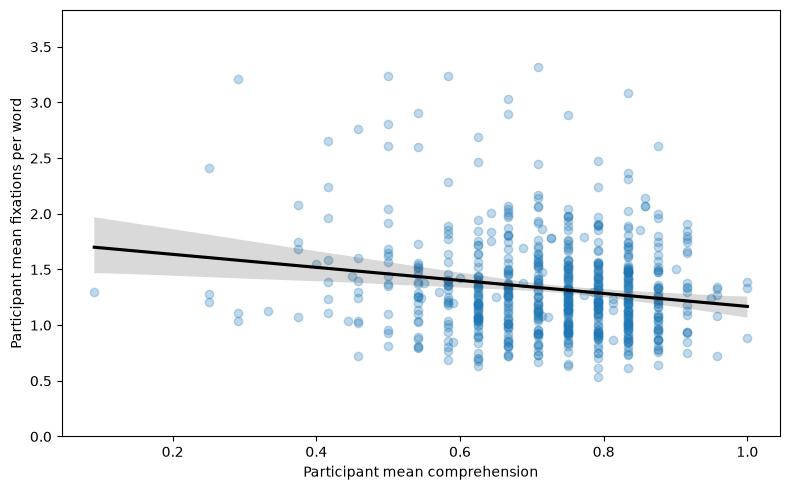

In [3]:
plotters = (plot_distributions, plot_jittered_association, plot_text_facets, plot_group_estimates, plot_language_text_heatmap, plot_participant_association)
for wave, data in wave_data.items():
    wave_output = OUTPUT / f'wave-{wave}' / 'plots'
    wave_output.mkdir(parents=True, exist_ok=True)
    display(Markdown(f'### Wave {wave}'))
    for plotter in plotters:
        fig = plotter(data, wave_output)
        for ax in fig.axes:
            if 'fixation' in ax.get_ylabel().lower() or 'word' in ax.get_ylabel().lower():
                ax.set_ylim(global_ylim)
        display(fig)
        plt.close(fig)

## Wave-Specific Models and Diagnostics

### Wave 1

,wave,n_rows,poisson_dispersion,estimate,rate_ratio,ci_low,ci_high,p_value
0,1,6501,16.480619,-0.005848,0.994169,0.98677,1.001624,0.12498


Reverse binomial model

,wave,n_rows,estimate,odds_ratio,ci_low,ci_high,p_value
0,1,6501,-0.228649,0.795608,0.70765,0.894497,0.000131


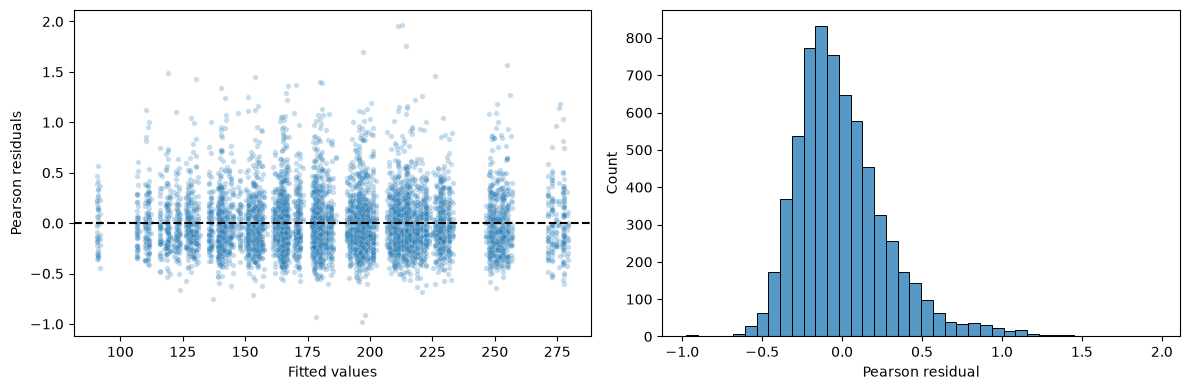

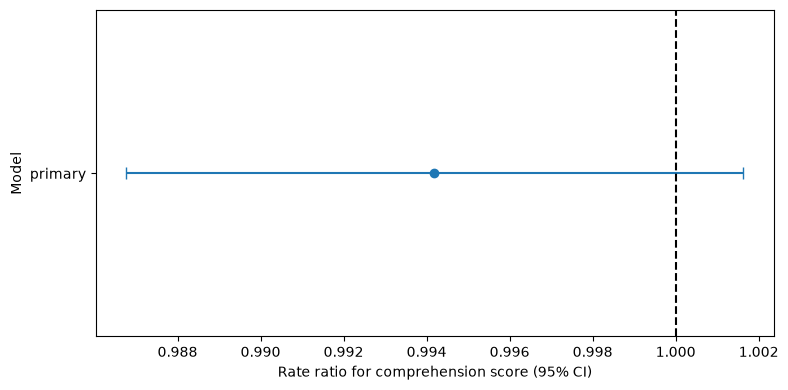

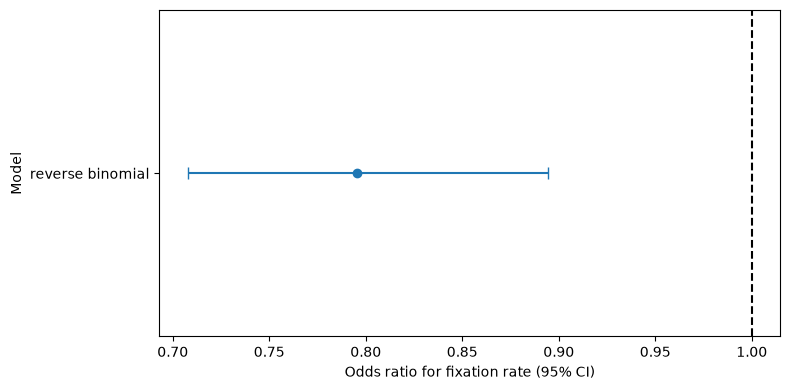

### Wave 2

,wave,n_rows,poisson_dispersion,estimate,rate_ratio,ci_low,ci_high,p_value
0,2,7695,15.952954,0.002101,1.002103,0.994373,1.009894,0.594886


Reverse binomial model

,wave,n_rows,estimate,odds_ratio,ci_low,ci_high,p_value
0,2,7695,-0.090354,0.913607,0.80922,1.031461,0.144408


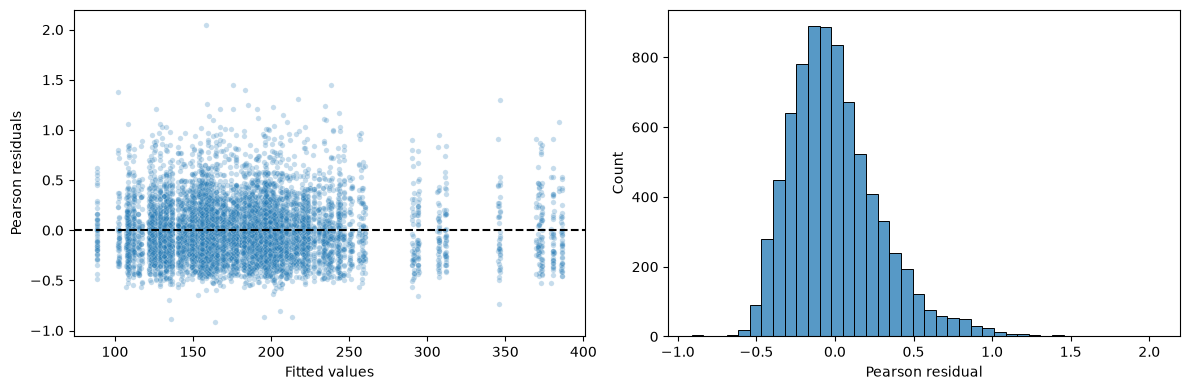

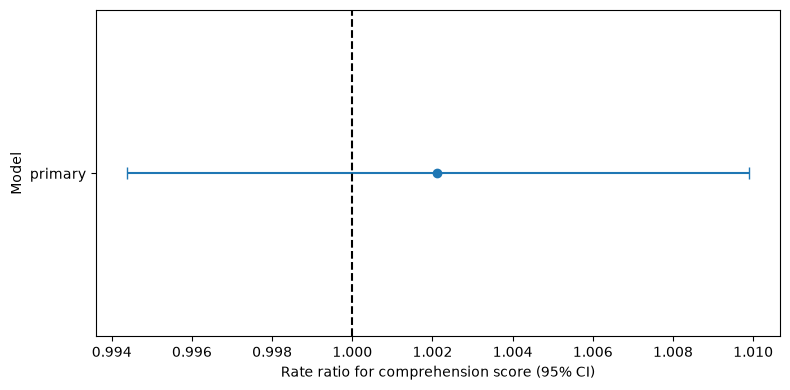

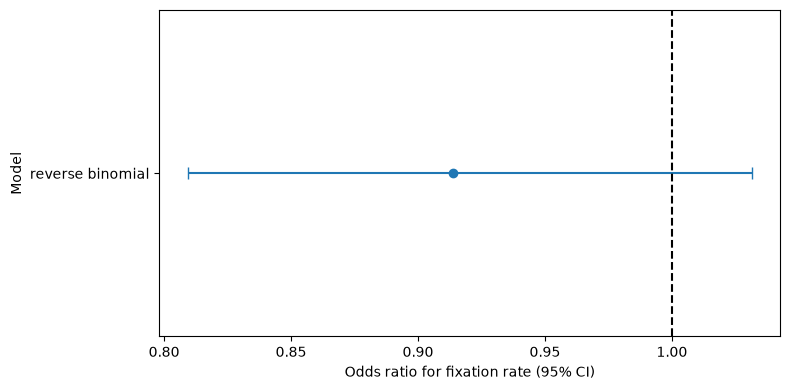

## Primary model comparison

,wave,n_rows,poisson_dispersion,estimate,rate_ratio,ci_low,ci_high,p_value
0,1,6501,16.480619,-0.005848,0.994169,0.986770,1.001624,0.124980
1,2,7695,15.952954,0.002101,1.002103,0.994373,1.009894,0.594886


## Reverse model comparison

,wave,n_rows,estimate,odds_ratio,ci_low,ci_high,p_value
0,1,6501,-0.228649,0.795608,0.70765,0.894497,0.000131
1,2,7695,-0.090354,0.913607,0.80922,1.031461,0.144408


In [4]:
model_results = {}
model_rows = []
reverse_rows = []
for wave, data in wave_data.items():
    wave_output = OUTPUT / f'wave-{wave}'
    poisson = fit_poisson_diagnostic(data)
    primary = fit_primary(data)
    reverse = fit_reverse(data)
    model_results[wave] = {'primary': primary, 'reverse': reverse}
    dispersion = float((poisson.resid_pearson ** 2).sum() / poisson.df_resid)
    coefficient = primary.params['comprehension_score']
    low, high = primary.conf_int().loc['comprehension_score']
    model_rows.append({'wave': wave, 'n_rows': len(data), 'poisson_dispersion': dispersion, 'estimate': coefficient, 'rate_ratio': np.exp(coefficient), 'ci_low': np.exp(low), 'ci_high': np.exp(high), 'p_value': primary.pvalues['comprehension_score']})
    reverse_coefficient = reverse.params['fixations_per_word']
    reverse_low, reverse_high = reverse.conf_int().loc['fixations_per_word']
    reverse_rows.append({'wave': wave, 'n_rows': len(data), 'estimate': reverse_coefficient, 'odds_ratio': np.exp(reverse_coefficient), 'ci_low': np.exp(reverse_low), 'ci_high': np.exp(reverse_high), 'p_value': reverse.pvalues['fixations_per_word']})
    display(Markdown(f'### Wave {wave}'))
    display(pd.DataFrame(model_rows[-1:], index=None))
    display(Markdown('Reverse binomial model'))
    display(pd.DataFrame(reverse_rows[-1:], index=None))
    fig = plot_model_diagnostics(primary, wave_output / 'plots', filename='primary_model_diagnostics.png')
    display(fig)
    plt.close(fig)
    fig = plot_model_coefficients({'primary': primary}, wave_output / 'plots')
    display(fig)
    plt.close(fig)
    fig = plot_model_effects({'reverse binomial': reverse}, 'fixations_per_word', wave_output / 'plots', filename='reverse_model_odds_ratio.png', xlabel='Odds ratio for fixation rate (95% CI)')
    display(fig)
    plt.close(fig)
comparison = pd.DataFrame(model_rows)
comparison.to_csv(OUTPUT / 'wave_model_comparison.csv', index=False)
reverse_comparison = pd.DataFrame(reverse_rows)
reverse_comparison.to_csv(OUTPUT / 'wave_reverse_model_comparison.csv', index=False)
display(Markdown('## Primary model comparison'))
display(comparison)
display(Markdown('## Reverse model comparison'))
display(reverse_comparison)

## Duration Sensitivity

The sensitivity model excludes participant-text groups containing a fixation duration above 2,000 ms. It is fitted independently within each wave.

In [5]:
sensitivity_rows = []
for wave, data in wave_data.items():
    filtered = data[data['duration_extreme_rows'] == 0].copy()
    sensitivity = fit_primary(filtered)
    low, high = sensitivity.conf_int().loc['comprehension_score']
    sensitivity_rows.append({'wave': wave, 'model': 'without extreme duration', 'n_rows': len(filtered), 'rate_ratio': np.exp(sensitivity.params['comprehension_score']), 'ci_low': np.exp(low), 'ci_high': np.exp(high), 'p_value': sensitivity.pvalues['comprehension_score']})
sensitivity_comparison = pd.DataFrame(sensitivity_rows)
sensitivity_comparison.to_csv(OUTPUT / 'duration_sensitivity_comparison.csv', index=False)
display(sensitivity_comparison)

,wave,model,n_rows,rate_ratio,ci_low,ci_high,p_value
0,1,without extreme duration,6455,0.993864,0.986525,1.001259,0.103663
1,2,without extreme duration,7632,1.002897,0.995099,1.010756,0.467661


## Interpretation

Compare effect direction and confidence intervals across the two independently fitted models. These are observational associations, not causal effects.